Using Colab cache for faster access to the 'ibm-hr-analytics-attrition-dataset' dataset.
Dataset loaded successfully!
Dataset shape: (1470, 35)
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4          

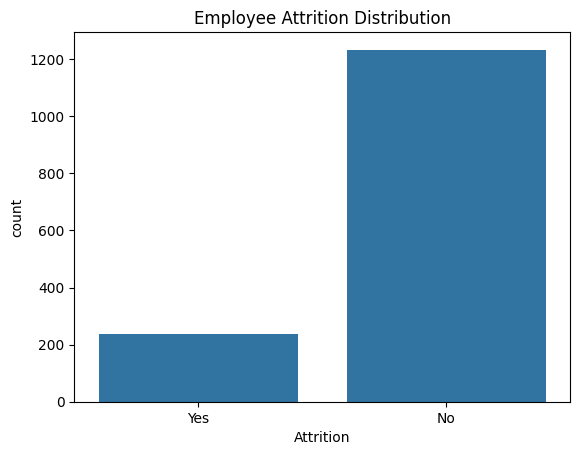


Model Comparison:
        Model  Accuracy  Precision  Recall  F1 Score
Decision Tree     0.780      0.378   0.576     0.456
Random Forest     0.864      0.800   0.203     0.324

Decision Tree Classification Report:
              precision    recall  f1-score   support

No Attrition       0.91      0.82      0.86       309
   Attrition       0.38      0.58      0.46        59

    accuracy                           0.78       368
   macro avg       0.64      0.70      0.66       368
weighted avg       0.82      0.78      0.80       368


Random Forest Classification Report:
              precision    recall  f1-score   support

No Attrition       0.87      0.99      0.92       309
   Attrition       0.80      0.20      0.32        59

    accuracy                           0.86       368
   macro avg       0.83      0.60      0.62       368
weighted avg       0.86      0.86      0.83       368



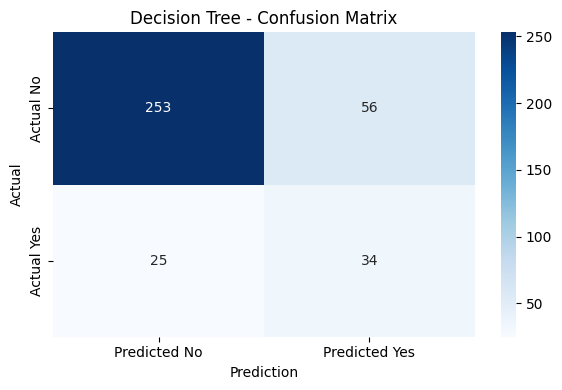

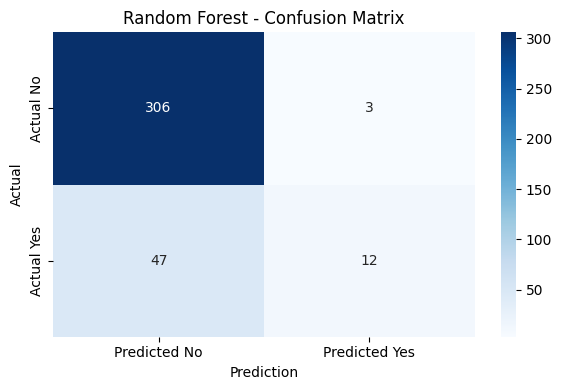


Top 10 Important Features:
MonthlyIncome           0.082398
OverTime_Yes            0.063851
Age                     0.063243
DailyRate               0.051378
TotalWorkingYears       0.045161
YearsAtCompany          0.044965
MonthlyRate             0.043271
YearsWithCurrManager    0.042050
DistanceFromHome        0.041283
HourlyRate              0.041014
dtype: float64


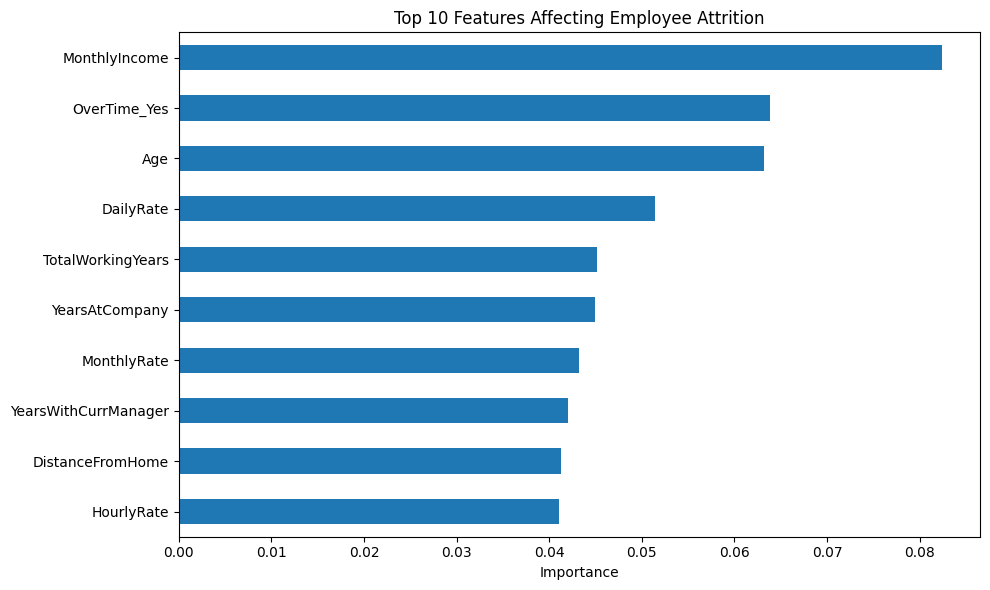


Best Model Based on F1 Score:
Model: Decision Tree
F1 Score: 0.456
Recall: 0.576
Accuracy: 0.78


In [6]:

!pip install -q kagglehub

import os
import glob
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Load Dataset
dataset_path = kagglehub.dataset_download(
    "pavansubhasht/ibm-hr-analytics-attrition-dataset"
)

csv_files = glob.glob(
    os.path.join(dataset_path, "**", "*.csv"),
    recursive=True
)

if not csv_files:
    raise FileNotFoundError("No CSV file found in the downloaded dataset.")

df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

# 2. Basic Data Analysis
print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nAttrition Distribution:")
print(df["Attrition"].value_counts())

sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Distribution")
plt.show()

# 3. Prepare Data
df = df.drop(
    columns=[
        "EmployeeNumber",
        "EmployeeCount",
        "Over18",
        "StandardHours"
    ],
    errors="ignore"
)

X = df.drop(columns=["Attrition"])
y = df["Attrition"].map({"Yes": 1, "No": 0})

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

# 4. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=10,
    stratify=y
)

# 5. Train Decision Tree
decision_tree = DecisionTreeClassifier(
    max_depth=6,
    min_samples_split=10,
    class_weight="balanced",
    random_state=10
)

decision_tree.fit(X_train, y_train)
tree_predictions = decision_tree.predict(X_test)

# 6. Train Random Forest
random_forest = RandomForestClassifier(
    n_estimators=150,
    max_depth=10,
    min_samples_split=5,
    class_weight="balanced",
    random_state=10
)

random_forest.fit(X_train, y_train)
forest_predictions = random_forest.predict(X_test)

# 7. Evaluate Models
models = {
    "Decision Tree": tree_predictions,
    "Random Forest": forest_predictions
}

results = []

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("\nModel Comparison:")
print(results_df.round(3).to_string(index=False))

# 8. Classification Reports
for model_name, predictions in models.items():
    print(f"\n{model_name} Classification Report:")
    print(
        classification_report(
            y_test,
            predictions,
            target_names=["No Attrition", "Attrition"],
            zero_division=0
        )
    )

# 9. Confusion Matrices
for model_name, predictions in models.items():
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted No", "Predicted Yes"],
        yticklabels=["Actual No", "Actual Yes"]
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Prediction")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

# 10. Feature Importance
feature_importance = pd.Series(
    random_forest.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop 10 Important Features:")
print(feature_importance.head(10))

plt.figure(figsize=(10, 6))
feature_importance.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Features Affecting Employee Attrition")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# 11. Final Result
best_model = results_df.loc[results_df["F1 Score"].idxmax()]

print("\nBest Model Based on F1 Score:")
print("Model:", best_model["Model"])
print("F1 Score:", round(best_model["F1 Score"], 3))
print("Recall:", round(best_model["Recall"], 3))
print("Accuracy:", round(best_model["Accuracy"], 3))

